--- STEP 1: UPLOAD DATASET ---
Please upload 'processed_data2.xlsx' or your CSV file.


Saving processed_data2.xlsx to processed_data2 (3).xlsx

--- Training Models ---

Model      | RMSE       | Corr       | Std Dev   
---------------------------------------------
LR         | 11.59      | 0.727      | 13.75     
KNN        | 14.59      | 0.528      | 15.74     
SVM        | 4.42       | 0.942      | 12.21     
MLP        | 9.03       | 0.844      | 16.25     
DT         | 7.75       | 0.837      | 13.63     
RF         | 23.17      | 0.353      | 23.91     
AB         | 40.65      | 0.093      | 39.23     
LB         | 11.54      | 0.698      | 13.32     
XB         | 7.87       | 0.819      | 12.81     


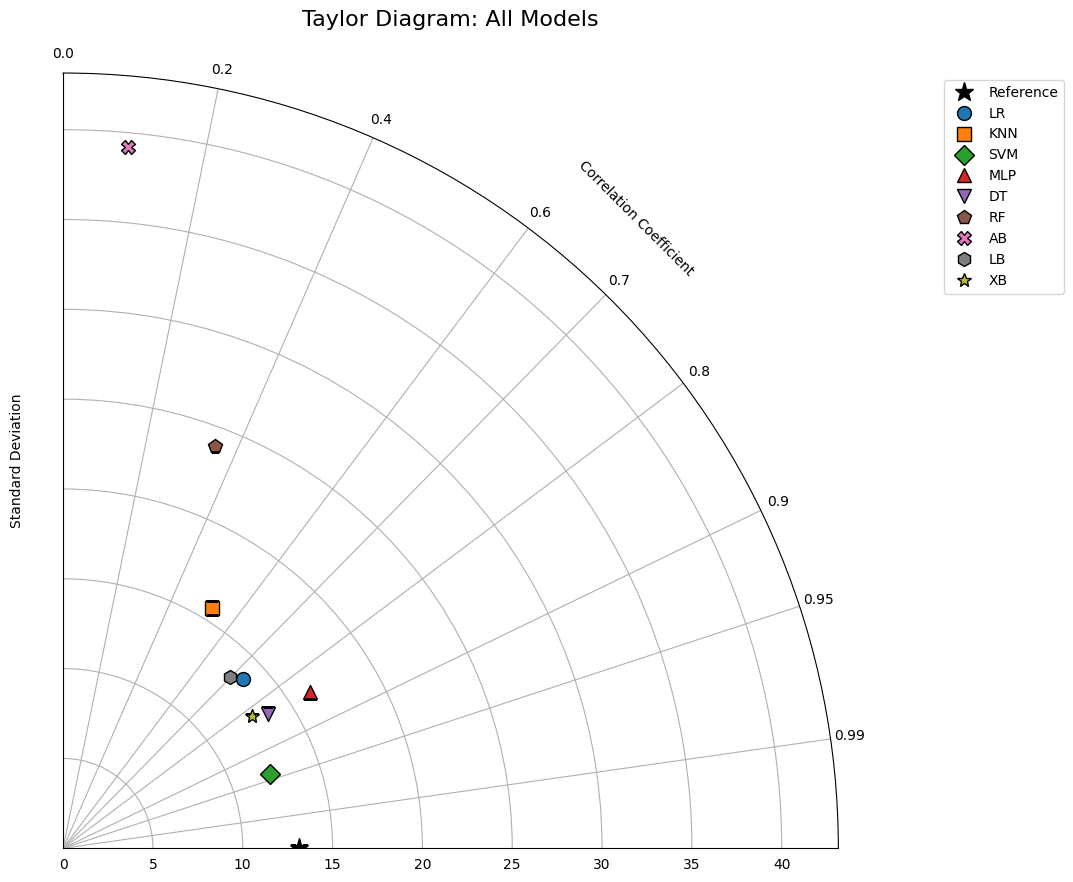

In [ ]:
# @title
# =========================================================
# TAYLOR DIAGRAM: COMPARING ALL MODELS
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import io
import warnings

# ML Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
import xgboost as xgb
import lightgbm as lgb
from google.colab import files

warnings.filterwarnings('ignore')

# 1. LOAD DATA
# ---------------------------------------------------------
print("--- STEP 1: UPLOAD DATASET ---")
print("Please upload 'processed_data2.xlsx' or your CSV file.")
uploaded = files.upload()
filename = next(iter(uploaded))

if filename.endswith('.xlsx'):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
else:
    df = pd.read_csv(io.BytesIO(uploaded[filename]))

target_col = df.columns[-1]
X = df.drop(columns=[target_col])
y = df[target_col]

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. PREPROCESSING (SCALING)
# ---------------------------------------------------------
# Essential for SVM, KNN, MLP, LR
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# 3. DEFINE ALL MODELS
# ---------------------------------------------------------
# We group them by whether they need scaling or not
models_needing_scaling = {
    "LR": LinearRegression(),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "SVM": SVR(C=100, epsilon=0.1),
    "MLP": MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)
}

models_tree_based = {
    "DT": DecisionTreeRegressor(max_depth=10, random_state=42),
    "RF": RandomForestRegressor(n_estimators=100, random_state=42),
    "AB": AdaBoostRegressor(n_estimators=50, random_state=42),
    "LB": lgb.LGBMRegressor(n_estimators=100, random_state=42, verbose=-1),
    "XB": xgb.XGBRegressor(n_estimators=100, random_state=42, verbosity=0)
}

predictions = {}

print("\n--- Training Models ---")

# Train Scale-Sensitive Models
for name, model in models_needing_scaling.items():
    model.fit(X_train_sc, y_train)
    predictions[name] = model.predict(X_test_sc)

# Train Tree-Based Models (Can use raw data)
for name, model in models_tree_based.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

# 4. PLOT TAYLOR DIAGRAM
# ---------------------------------------------------------
def plot_taylor_diagram(ref, preds_dict):
    ref_std = np.std(ref)

    fig = plt.figure(figsize=(11, 11))
    ax = fig.add_subplot(111, polar=True)

    # Quarter Circle Configuration
    ax.set_thetamin(0)
    ax.set_thetamax(90)

    # Plot Reference (The "Truth")
    ax.plot([0], [ref_std], 'k*', markersize=14, label='Reference')

    # Calculate limits
    max_std = ref_std
    for p in preds_dict.values():
        max_std = max(max_std, np.std(p))
    ax.set_rlim(0, max_std * 1.1)

    # Grid Setup
    r_labels = [0.99, 0.95, 0.9, 0.8, 0.7, 0.6, 0.4, 0.2, 0.0]
    t_locs = np.arccos(r_labels)
    ax.set_thetagrids(np.degrees(t_locs), labels=r_labels)
    ax.set_ylabel('Standard Deviation', labelpad=25)
    ax.text(np.radians(45), max_std * 1.15, "Correlation Coefficient", rotation=-45, ha='center')

    # Plotting Loop
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
              '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22']
    markers = ['o', 's', 'D', '^', 'v', 'p', 'X', 'h', '*']

    print(f"\n{'Model':<10} | {'RMSE':<10} | {'Corr':<10} | {'Std Dev':<10}")
    print("-" * 45)

    for i, (name, pred) in enumerate(preds_dict.items()):
        std = np.std(pred)
        corr = np.corrcoef(ref, pred)[0, 1]
        rmse = np.sqrt(mean_squared_error(ref, pred))

        # Polar Coordinates
        theta = np.arccos(corr)
        r = std

        ax.plot(theta, r, marker=markers[i % len(markers)],
                color=colors[i % len(colors)], linestyle='None',
                label=name, markersize=10, markeredgecolor='black')

        print(f"{name:<10} | {rmse:<10.2f} | {corr:<10.3f} | {std:<10.2f}")

    ax.set_title("Taylor Diagram: All Models", y=1.05, fontsize=16)
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))
    plt.tight_layout()
    plt.show()

plot_taylor_diagram(y_test, predictions)

--- STEP 1: UPLOAD DATASET ---
Please upload 'processed_data2.xlsx' or your CSV file.


Saving processed_data2.xlsx to processed_data2 (4).xlsx

Dataset Loaded: 147 rows, 7 columns

--- STEP 2: RUNNING SIMULATION (20 iterations) ---
Processing run 5/20...
Processing run 10/20...
Processing run 15/20...
Processing run 20/20...

--- STEP 3: AGGREGATING RESULTS ---

--- STEP 4: GENERATING FIGURE 11 ---


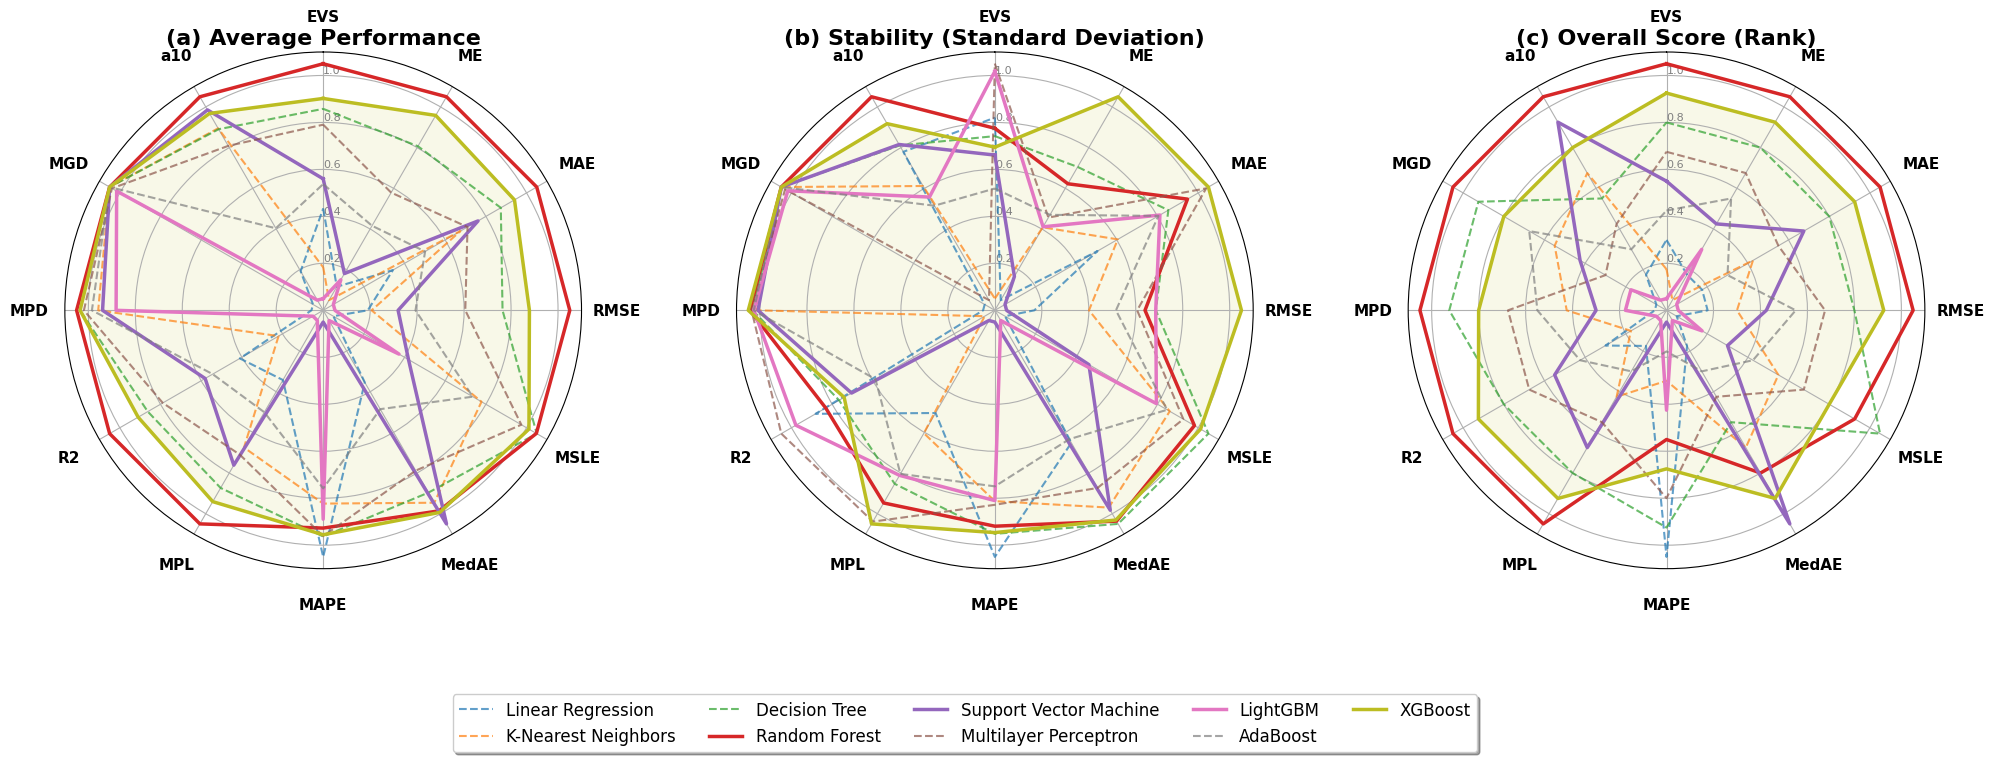

Process Completed.


In [ ]:
# @title
# =============================================================================
# AUTOMATED MODEL BENCHMARKING & RADAR PLOTTING (PROFESSIONAL EDITION)
# =============================================================================
# Author: Research Assistant AI
# Updates:
#   - Enhanced plotting layout to prevent text overlap.
#   - Full model names in legend.
#   - Clear distinction between top-tier and lower-tier models.
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
import io
import warnings

# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error, max_error,
    mean_squared_log_error, median_absolute_error,
    mean_absolute_percentage_error, explained_variance_score,
    mean_poisson_deviance, mean_gamma_deviance
)
import xgboost as xgb
import lightgbm as lgb
from google.colab import files

# Suppress warnings
warnings.filterwarnings('ignore')

# =============================================================================
# 1. DATA UPLOAD & PREPROCESSING
# =============================================================================
print("--- STEP 1: UPLOAD DATASET ---")
print("Please upload 'processed_data2.xlsx' or your CSV file.")
uploaded = files.upload()
filename = next(iter(uploaded))

# Load Data
if filename.endswith('.xlsx'):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
else:
    df = pd.read_csv(io.BytesIO(uploaded[filename]))

print(f"\nDataset Loaded: {df.shape[0]} rows, {df.shape[1]} columns")

# Detect Target Column (Assumes last column is target)
target_col = df.columns[-1]
X = df.drop(columns=[target_col])
y = df[target_col]

# =============================================================================
# 2. CONFIGURATION: METRICS & MODELS
# =============================================================================

# Custom Metrics
def mean_pinball_loss(y_true, y_pred, alpha=0.5):
    diff = y_true - y_pred
    return np.mean(np.maximum(alpha * diff, (alpha - 1) * diff))

def a10_index(y_true, y_pred):
    y_true_safe = np.where(y_true == 0, 1e-6, y_true)
    ratio = y_pred / y_true_safe
    return np.mean((ratio >= 0.9) & (ratio <= 1.1))

# Metrics Configuration
metrics_config = {
    'EVS':   {'func': explained_variance_score, 'dir': 1},
    'ME':    {'func': max_error, 'dir': 0},
    'MAE':   {'func': mean_absolute_error, 'dir': 0},
    'RMSE':  {'func': lambda yt, yp: np.sqrt(mean_squared_error(yt, yp)), 'dir': 0},
    'MSLE':  {'func': mean_squared_log_error, 'dir': 0},
    'MedAE': {'func': median_absolute_error, 'dir': 0},
    'MAPE':  {'func': mean_absolute_percentage_error, 'dir': 0},
    'MPL':   {'func': mean_pinball_loss, 'dir': 0},
    'R2':    {'func': r2_score, 'dir': 1},
    'MPD':   {'func': mean_poisson_deviance, 'dir': 0},
    'MGD':   {'func': mean_gamma_deviance, 'dir': 0},
    'a10':   {'func': a10_index, 'dir': 1}
}

# Models Configuration
models = {
    "LR":  LinearRegression(),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "DT":  DecisionTreeRegressor(max_depth=10, random_state=42),
    "RF":  RandomForestRegressor(n_estimators=100, random_state=42),
    "SVM": SVR(C=100, epsilon=0.1),
    "MLP": MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42),
    "LB":  lgb.LGBMRegressor(n_estimators=100, random_state=42, verbose=-1),
    "AB":  AdaBoostRegressor(n_estimators=50, random_state=42),
    "XB":  xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0)
}

# Legend Name Mapping (For Professional Labels)
legend_names = {
    "LR": "Linear Regression",
    "KNN": "K-Nearest Neighbors",
    "DT": "Decision Tree",
    "RF": "Random Forest",
    "SVM": "Support Vector Machine",
    "MLP": "Multilayer Perceptron",
    "LB": "LightGBM",
    "AB": "AdaBoost",
    "XB": "XGBoost"
}

# =============================================================================
# 3. MONTE CARLO SIMULATION
# =============================================================================
N_SIMULATIONS = 20
results_storage = {m: {met: [] for met in metrics_config} for m in models}

print(f"\n--- STEP 2: RUNNING SIMULATION ({N_SIMULATIONS} iterations) ---")

for i in range(N_SIMULATIONS):
    if (i+1) % 5 == 0: print(f"Processing run {i+1}/{N_SIMULATIONS}...")

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=i)

    # Scaling
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)

    for name, model in models.items():
        try:
            model.fit(X_train_sc, y_train)
            preds = model.predict(X_test_sc)

            preds = np.maximum(preds, 1e-6)
            y_test_safe = np.maximum(y_test, 1e-6)

            for met_name, config in metrics_config.items():
                if met_name in ['MSLE', 'MPD', 'MGD']:
                    score = config['func'](y_test_safe, preds)
                else:
                    score = config['func'](y_test, preds)
                results_storage[name][met_name].append(score)
        except Exception:
            continue

# =============================================================================
# 4. AGGREGATION & NORMALIZATION
# =============================================================================
print("\n--- STEP 3: AGGREGATING RESULTS ---")

df_avg = pd.DataFrame(index=metrics_config.keys(), columns=models.keys())
df_std = pd.DataFrame(index=metrics_config.keys(), columns=models.keys())

for model in models:
    for metric in metrics_config:
        vals = results_storage[model][metric]
        if vals:
            df_avg.loc[metric, model] = np.mean(vals)
            df_std.loc[metric, model] = np.std(vals)
        else:
            df_avg.loc[metric, model] = 0.0
            df_std.loc[metric, model] = 0.0

def normalize_data(df_input, is_std=False):
    df_norm = df_input.copy()
    for metric in df_norm.index:
        vals = df_input.loc[metric].astype(float)
        min_v, max_v = vals.min(), vals.max()
        range_v = max_v - min_v if (max_v - min_v) > 0 else 1.0

        if is_std:
            df_norm.loc[metric] = (max_v - vals) / range_v
        else:
            if metrics_config[metric]['dir'] == 1:
                df_norm.loc[metric] = (vals - min_v) / range_v
            else:
                df_norm.loc[metric] = (max_v - vals) / range_v
    return df_norm.astype(float)

df_avg_norm = normalize_data(df_avg, is_std=False)
df_std_norm = normalize_data(df_std, is_std=True)

df_rank = pd.DataFrame(index=metrics_config.keys(), columns=models.keys())
for metric in metrics_config:
    vals = df_avg.loc[metric].astype(float)
    if metrics_config[metric]['dir'] == 1:
        df_rank.loc[metric] = vals.rank(ascending=True)
    else:
        df_rank.loc[metric] = vals.rank(ascending=False)

df_score_norm = (df_rank - 1) / (len(models) - 1)

# =============================================================================
# 5. PROFESSIONAL RADAR PLOTTING
# =============================================================================
def plot_radar_enhanced(df, title, ax):
    # Setup Geometry
    categories = list(df.index)
    N = len(categories)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]

    # Draw Axes with specific offset to prevent rotation issues
    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)

    # Label adjustments (Padding to prevent overlap)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, size=11, fontweight='bold')
    ax.tick_params(axis='x', pad=15) # Pushes labels out

    # Y-labels (Grid Lines)
    ax.set_rlabel_position(0)
    plt.yticks([0.2, 0.4, 0.6, 0.8, 1.0], ["0.2","0.4","0.6","0.8","1.0"], color="grey", size=8)
    plt.ylim(0, 1.1)

    # Distinct Colors
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
              '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22']

    # Plot Each Model
    for i, model in enumerate(df.columns):
        values = df[model].values.flatten().tolist()
        values += values[:1]

        # Use Full Name for Label if plotting, else code
        full_name = legend_names.get(model, model)

        # Highlight Top Tier (Solid) vs Lower Tier (Dashed)
        # Assuming Tree models and SVM are top tier for this visual
        if model in ['XB', 'LB', 'RF', 'SVM']:
            ax.plot(angles, values, linewidth=2.5, linestyle='solid', label=full_name, color=colors[i])
            # Optional: Add fill for the very best one (usually XB) to make it pop
            if model == 'XB':
                ax.fill(angles, values, color=colors[i], alpha=0.1)
        else:
            ax.plot(angles, values, linewidth=1.5, linestyle='dashed', label=full_name, color=colors[i], alpha=0.7)

    # Title Positioning
    ax.set_title(title, size=16, weight='bold', position=(0.5, 1.15))

print("\n--- STEP 4: GENERATING FIGURE 11 ---")
# Increased Figure Height for clearer layout
fig = plt.figure(figsize=(24, 9))

# Plot A: Average
ax1 = plt.subplot(131, polar=True)
plot_radar_enhanced(df_avg_norm + 0.05, "(a) Average Performance", ax1)

# Plot B: Standard Deviation
ax2 = plt.subplot(132, polar=True)
plot_radar_enhanced(df_std_norm + 0.05, "(b) Stability (Standard Deviation)", ax2)

# Plot C: Score (Rank)
ax3 = plt.subplot(133, polar=True)
plot_radar_enhanced(df_score_norm + 0.05, "(c) Overall Score (Rank)", ax3)

# Shared Legend at Bottom with ample space
# We pull labels from the first plot, but ensure we have all of them
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 0.0),
           ncol=5, fontsize=12, frameon=True, fancybox=True, shadow=True)

# Adjust spacing to prevent title/legend collision
plt.subplots_adjust(top=0.85, bottom=0.15, wspace=0.3)

plt.show()
print("Process Completed.")

--- STEP 1: UPLOAD DATASET ---
Please upload 'processed_data2.xlsx' or your CSV file.


Saving processed_data2.xlsx to processed_data2 (1).xlsx

Data Loaded. Features: 6, Samples: 147

--- STEP 2: RUNNING GRID SEARCH & PLOTTING ---
Optimizing KNN...
Optimizing DT...
Optimizing MLP...
Optimizing RF...
Optimizing SVM...
Optimizing LB...
Optimizing AB...
Optimizing XB...


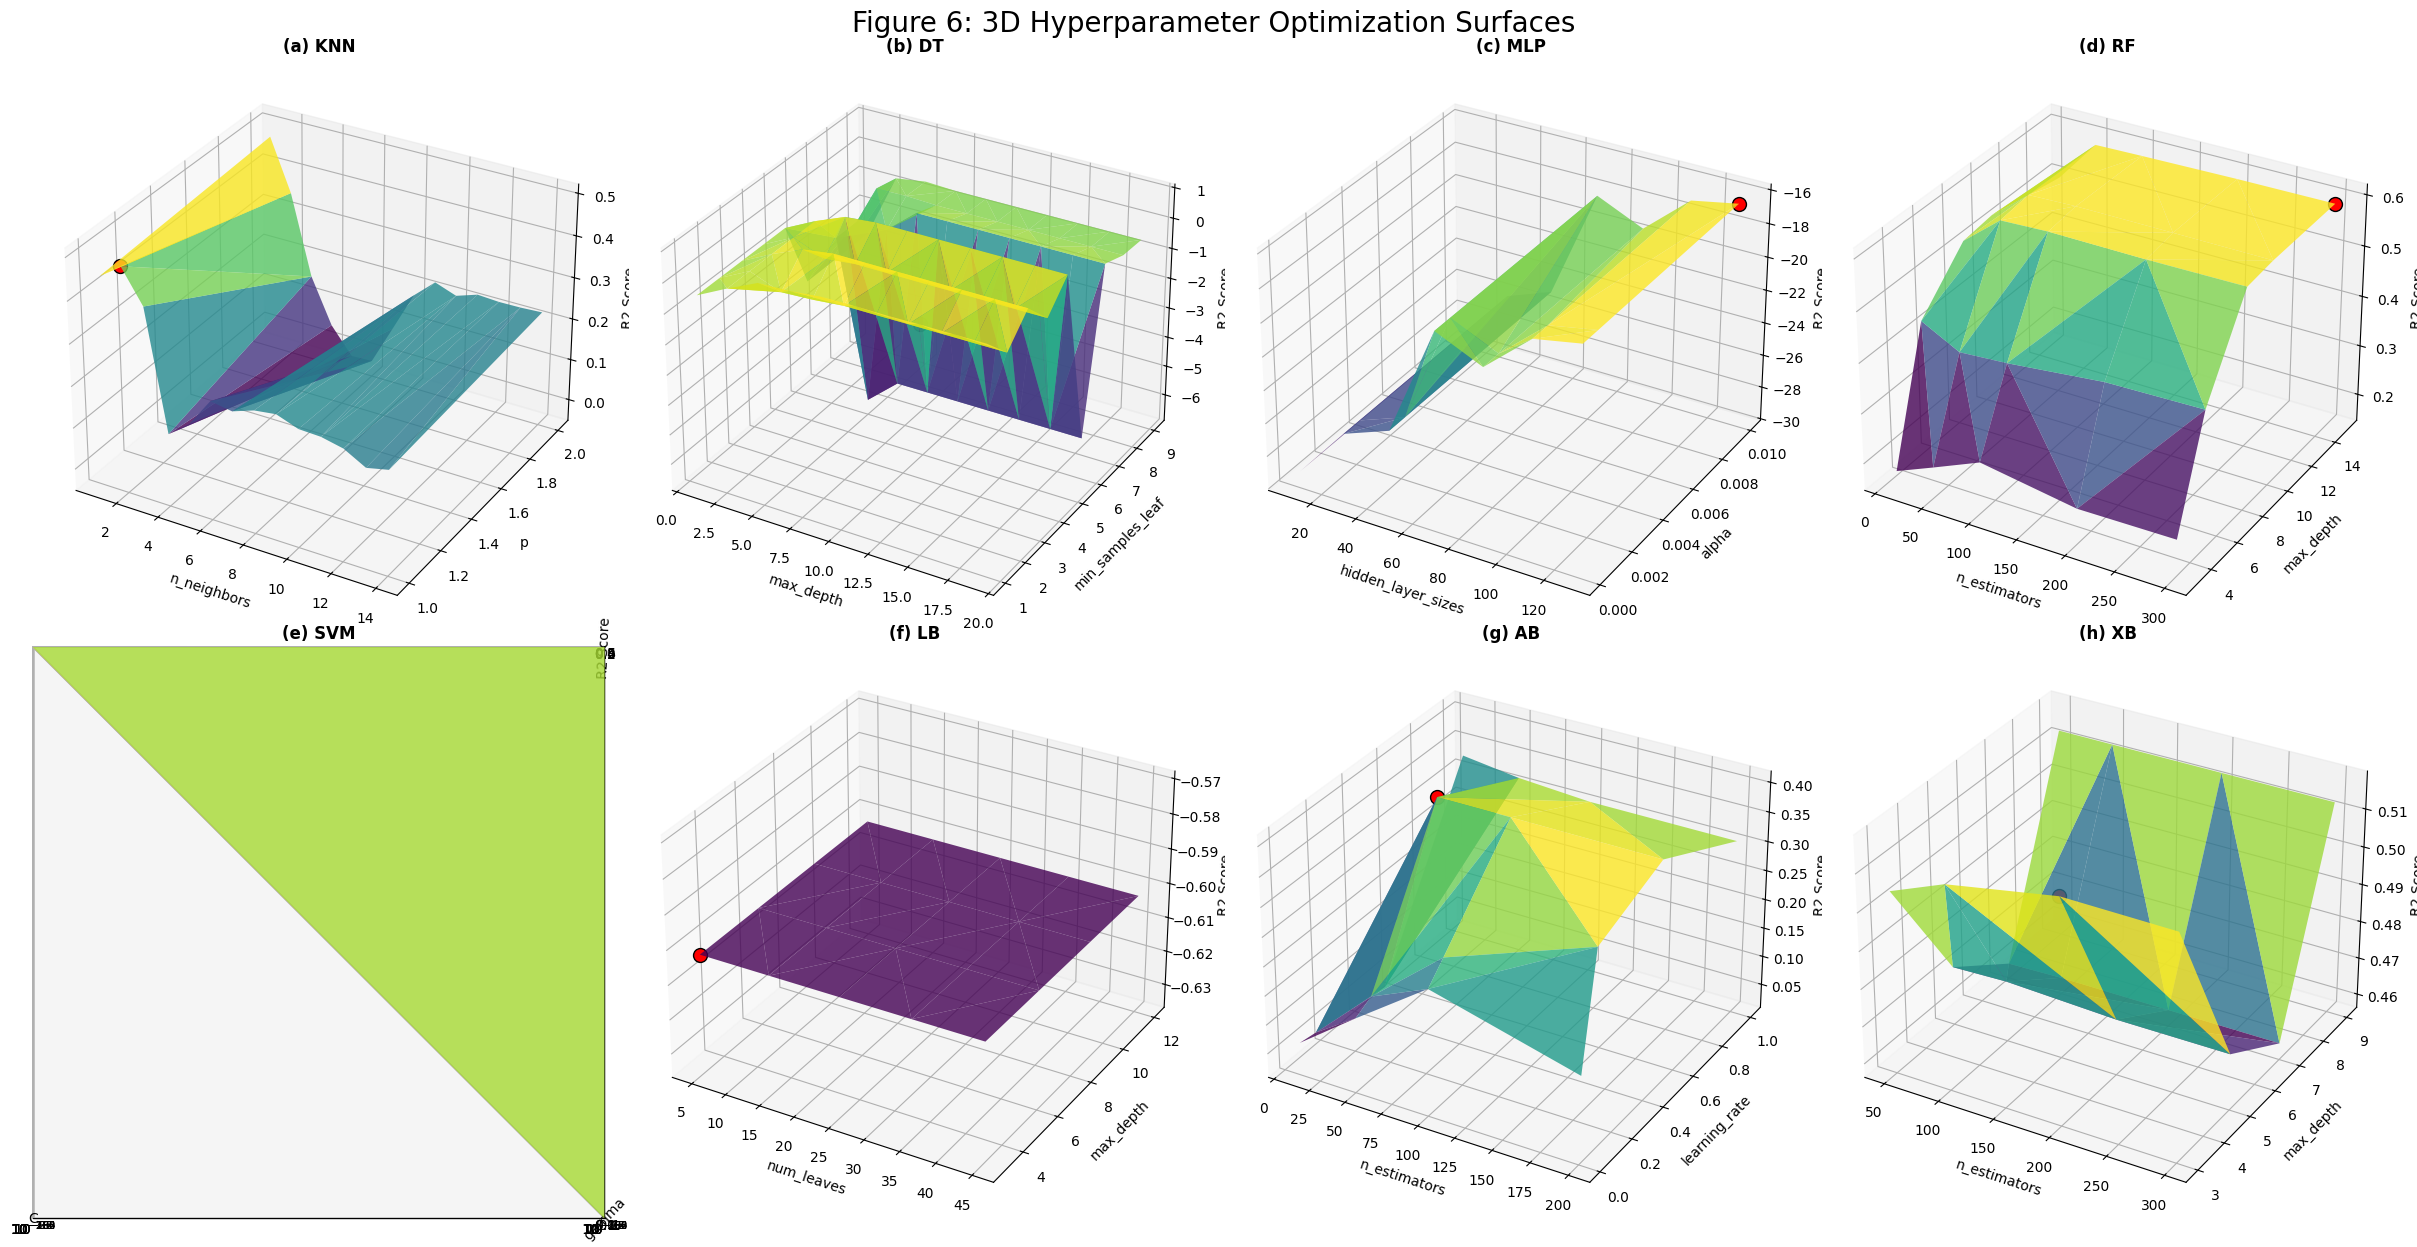


Processing Complete.


In [ ]:
# @title
# =========================================================
# 3D HYPERPARAMETER OPTIMIZATION (GRID SEARCH)
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import io
import warnings

# ML Libraries
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.svm import SVR
import lightgbm as lgb
import xgboost as xgb
from google.colab import files

warnings.filterwarnings('ignore')

# 1. LOAD DATA (FROM FILE)
# ---------------------------------------------------------
print("--- STEP 1: UPLOAD DATASET ---")
print("Please upload 'processed_data2.xlsx' or your CSV file.")
uploaded = files.upload()
filename = next(iter(uploaded))

# Load Data
if filename.endswith('.xlsx'):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
else:
    df = pd.read_csv(io.BytesIO(uploaded[filename]))

# Detect Target (Last Column)
target_col = df.columns[-1]
X = df.drop(columns=[target_col])
y = df[target_col]

print(f"\nData Loaded. Features: {X.shape[1]}, Samples: {X.shape[0]}")

# Preprocessing (Scaling is crucial for KNN, SVM, MLP)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. DEFINING GRIDS (The "Search Space")
# ---------------------------------------------------------
# We search for the best combination of 2 parameters for each model
grids = {
    'KNN': {
        'model': KNeighborsRegressor(),
        'params': {'n_neighbors': np.arange(1, 15, 1), 'p': [1, 2]},
        'axes': ['n_neighbors', 'p'] # p=1 (Manhattan), p=2 (Euclidean)
    },
    'DT': {
        'model': DecisionTreeRegressor(random_state=42),
        'params': {'max_depth': np.arange(1, 20, 2), 'min_samples_leaf': np.arange(1, 10, 1)},
        'axes': ['max_depth', 'min_samples_leaf']
    },
    'MLP': {
        'model': MLPRegressor(random_state=42, max_iter=200),
        # hidden_layer_sizes must be tuples for sklearn, e.g. (10,), (30,)
        'params': {'hidden_layer_sizes': [(i,) for i in range(10, 150, 20)], 'alpha': [0.0001, 0.001, 0.01]},
        'axes': ['hidden_layer_sizes', 'alpha']
    },
    'RF': {
        'model': RandomForestRegressor(random_state=42),
        'params': {'n_estimators': [10, 50, 100, 200, 300], 'max_depth': [3, 5, 8, 10, 15]},
        'axes': ['n_estimators', 'max_depth']
    },
    'SVM': {
        'model': SVR(),
        'params': {'C': [0.1, 1, 10, 100, 1000], 'gamma': [0.001, 0.01, 0.1, 1]},
        'axes': ['C', 'gamma']
    },
    'LB': {
        'model': lgb.LGBMRegressor(random_state=42, verbose=-1),
        'params': {'num_leaves': np.arange(5, 50, 10), 'max_depth': np.arange(3, 15, 3)},
        'axes': ['num_leaves', 'max_depth']
    },
    'AB': {
        'model': AdaBoostRegressor(random_state=42),
        'params': {'n_estimators': [10, 50, 100, 200], 'learning_rate': [0.01, 0.1, 0.5, 1.0]},
        'axes': ['n_estimators', 'learning_rate']
    },
    'XB': {
        'model': xgb.XGBRegressor(random_state=42, verbosity=0),
        'params': {'n_estimators': [50, 100, 200, 300], 'max_depth': [3, 5, 7, 9]},
        'axes': ['n_estimators', 'max_depth']
    }
}

# 3. PLOTTING LOOP
# ---------------------------------------------------------
print("\n--- STEP 2: RUNNING GRID SEARCH & PLOTTING ---")
fig = plt.figure(figsize=(24, 12))
plt.subplots_adjust(wspace=0.3, hspace=0.3)

for idx, (name, config) in enumerate(grids.items()):
    print(f"Optimizing {name}...")

    # Run Grid Search
    # This tries every combination (e.g., 5 estimators * 5 depths = 25 runs)
    gs = GridSearchCV(config['model'], config['params'], cv=3, scoring='r2')

    # Use scaled data for distance-based models, raw for trees
    if name in ['KNN', 'SVM', 'MLP']:
        gs.fit(X_scaled, y)
    else:
        gs.fit(X, y)

    # Extract results for plotting
    results = pd.DataFrame(gs.cv_results_)
    param_names = list(config['params'].keys())
    x_name, y_name = param_names[0], param_names[1]

    # Prepare data for 3D plot
    # Handle the tuple structure of MLP layers for plotting
    if name == 'MLP':
        X_axis = np.array([x[0] for x in results[f'param_{x_name}']])
    else:
        X_axis = results[f'param_{x_name}'].astype(float)

    Y_axis = results[f'param_{y_name}'].astype(float)
    Z_axis = results['mean_test_score'] # The R2 Score

    # Create 3D Subplot
    ax = fig.add_subplot(2, 4, idx+1, projection='3d')

    # Surface Plot
    surf = ax.plot_trisurf(X_axis, Y_axis, Z_axis, cmap='viridis', edgecolor='none', alpha=0.8)

    # Labels
    ax.set_xlabel(x_name)
    ax.set_ylabel(y_name)
    ax.set_zlabel('R2 Score')
    ax.set_title(f"({chr(97+idx)}) {name}", fontweight='bold')

    # Log scale for SVM helps visualize C/Gamma better
    if name == 'SVM':
        ax.set_xscale('log')
        ax.set_yscale('log')

    # Highlight the Best Point (The Peak)
    best_idx = gs.best_index_
    ax.scatter(X_axis[best_idx], Y_axis[best_idx], Z_axis[best_idx], color='red', s=100, label='Best', edgecolors='black')

plt.tight_layout()
plt.suptitle("Figure 6: 3D Hyperparameter Optimization Surfaces", fontsize=20, y=1.02)
plt.show()

print("\nProcessing Complete.")